In [1]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model 
from langchain_tavily import TavilySearch # web search
from langchain.agents import create_agent 
from langgraph.checkpoint.memory import MemorySaver # Memory for teh agent's context
load_dotenv()  # Load environment variables from .env file

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")

memory = MemorySaver()
llmGPT = init_chat_model("gpt-4.1") # initialize a chat model with the name "gpt-4"
tavilyTool = TavilySearch(max_results=2) #tavily object 
config = {"configurable" : {"thread_id" : "6"}} #config thread

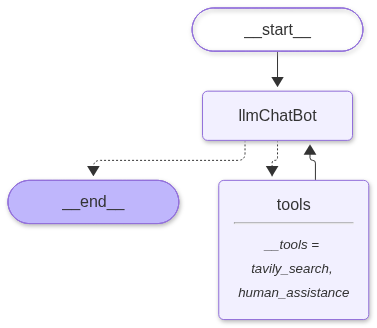

In [2]:
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition #langraph has a prebuilt node specifaclly for tools

from langchain_core.tools import tool
from langgraph.types import Command, interrupt #


class State(TypedDict):
    messages: Annotated[list, add_messages]



@tool
def human_assistance(query: str) -> str: 
    """Request Assistance from a human"""
    human_response = interrupt({"query" : query})
    return human_response["data"]


tools = [tavilyTool, human_assistance]
llm_with_tools = llmGPT.bind_tools(tools)



def chatbot(state: State):
    "This function calls llm tools"
    return {"messages": [llm_with_tools.invoke(state["messages"], config=config)]}



#graph - Nodes
graph_builder = StateGraph(State)
graph_builder.add_node("llmChatBot", chatbot)
graph_builder.add_node("tools", ToolNode(tools))

#graph - Edges
graph_builder.add_edge(START, "llmChatBot")
graph_builder.add_conditional_edges("llmChatBot", tools_condition)
graph_builder.add_edge("tools", "llmChatBot")
graph_builder.add_edge("llmChatBot", END)


graph = graph_builder.compile(checkpointer=memory)
graph



In [9]:
user_input = "Use the assistance tool to help me build an AI agent."
config = {"configurable" : {"thread_id" : "1"}}


events = graph.stream({"messages" : user_input}, config=config, stream_mode="values")

for event in events: 
    if "messages" in event: 
        event["messages"][-1].pretty_print()

================================ Human Message =================================

Use the assistance tool to help me build an AI agent.
================================== Ai Message ==================================

To proceed, I will use the assistance tool to connect you with a human AI expert who can guide you step-by-step in building your AI agent, including advice on:

- Defining your agent’s purpose and use case
- Choosing frameworks (such as LangGraph or others)
- Setting up your development environment
- Designing the agent’s architecture and workflow
- Integrating language models and APIs
- Implementing and testing functionalities

Please hold on while I request specialized human assistance for your project.
Tool Calls:
  human_assistance (call_RDVmZh91nQBbkpv5XmbIgleg)
 Call ID: call_RDVmZh91nQBbkpv5XmbIgleg
  Args:
    query: The user wants step-by-step help building an AI agent. They may need practical guidance on defining the agent's purpose, picking appropriate framewor

In [11]:
human_response = (
    "We recommend using LangGraph to build AI agents because it is "
    "reliable and extensible."
)

human_command = Command(
    resume={"data": human_response}
)

all_events = graph.stream(
    human_command,
    config=config,
    stream_mode="values"
)

for event in all_events:
    if "messages" in event: 
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================

I recommend using LangGraph to build your AI agent, as it is reliable and extensible. If you’d like, I can help you with detailed, step-by-step instructions for building your agent from scratch with LangGraph, including setup, design, and implementation guidance tailored to your needs. 

Please let me know your specific goals or desired use case, and I’ll provide exactly the assistance you require!
